# Tiền xử lý và Chuẩn hóa ảnh mống mắt CASIA-Iris-Thousand

Notebook này thực hiện giai đoạn tiền xử lý toàn bộ tập ảnh **CASIA-Iris-Thousand** nhằm phục vụ đồng thời cả hai hướng tiếp cận **Truyền thống** và **Học sâu**:
- **Khử phản xạ sáng (Specular Inpainting):** Phát hiện và nội suy vùng chói đèn hồng ngoại hoặc phản xạ tròng kính.
- **Định vị và Phân đoạn (Localization & Segmentation):** Xác định biên đồng tử bằng lọc đường viền thích nghi kết hợp toán tử vi phân tích phân Daugman (IDO) và tìm biên ngoài mống mắt theo hai cung bên nhằm hạn chế ảnh hưởng của mí mắt/lông mi.
- **Chuẩn hóa Daugman Rubber Sheet:** Trải phẳng vùng vành khăn mống mắt thành ảnh cực `64 × 256`, tạo mặt nạ điểm ảnh hợp lệ (`valid_mask`) và tăng cường tương phản cục bộ **CLAHE**.
- **Trích xuất vùng ảnh ROI (`224 × 224`):** Cắt vùng vuông bao quanh mống mắt phục vụ huấn luyện các mạng CNN.

## 1. Thiết lập môi trường, đồng bộ mã nguồn và nạp cấu hình

Kết nối Google Drive, đồng bộ mã nguồn dự án và đọc các siêu tham số tiền xử lý từ `configs/preprocessing_config.yaml`.

In [1]:
import os
import sys
import subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Badan174/Project3-Iris.git"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/prj3")
    DRIVE_PROJECT_DIR.mkdir(parents=True, exist_ok=True)
    WORK_DIR = Path("/content/Project3-Iris")

    if not WORK_DIR.exists():
        subprocess.run(["git", "clone", REPO_URL, str(WORK_DIR)], check=True)
    else:
        subprocess.run(["git", "-C", str(WORK_DIR), "pull"], check=True)

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "opencv-python-headless", "pyyaml", "tqdm"],
        check=True,
    )
    DATA_ROOT = Path("/content/data")
    PROCESSED_DIR = Path("/content/processed")
else:
    DRIVE_PROJECT_DIR = None
    WORK_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DATA_ROOT = WORK_DIR / "data" / "raw"
    PROCESSED_DIR = WORK_DIR / "data" / "processed"

DATA_ROOT.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
if str(WORK_DIR) not in sys.path:
    sys.path.insert(0, str(WORK_DIR))

print("Môi trường Colab   :", IN_COLAB)
print("Thư mục mã nguồn   :", WORK_DIR)
print("Thư mục dữ liệu    :", DATA_ROOT)
print("Thư mục đầu ra     :", PROCESSED_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Môi trường Colab   : True
Thư mục mã nguồn   : /content/Project3-Iris
Thư mục dữ liệu    : /content/data
Thư mục đầu ra     : /content/processed


In [2]:
import json
import shutil
import zipfile

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import yaml

from src.preprocessing import (
    SegmentationResult,
    archive_processed_dir,
    draw_segmentation_overlay,
    preprocess_dataset,
    preprocess_single_image,
)

with open(WORK_DIR / "configs" / "preprocessing_config.yaml", "r", encoding="utf-8") as f:
    PREP_CONFIG = yaml.safe_load(f)

METADATA_CSV = WORK_DIR / "data" / "splits" / "metadata.csv"
PREP_FIG_DIR = WORK_DIR / "results" / "preprocessing"
PREP_FIG_DIR.mkdir(parents=True, exist_ok=True)

meta_df = pd.read_csv(METADATA_CSV, dtype={"subject_id": str})
print(f"Nạp metadata thành công: {len(meta_df):,} bản ghi")
print("Kích thước Rubber Sheet:", PREP_CONFIG["normalization"]["radial_res"], "x", PREP_CONFIG["normalization"]["angular_res"])
print("Kích thước ROI         :", PREP_CONFIG["roi"]["output_size"], "x", PREP_CONFIG["roi"]["output_size"])

Nạp metadata thành công: 20,000 bản ghi
Kích thước Rubber Sheet: 64 x 256
Kích thước ROI         : 224 x 224


## 2. Giải nén dữ liệu gốc CASIA-Iris-Thousand

Tệp nén lưu trên Google Drive (`MyDrive/prj3/CASIA-Iris-Thousand.zip`) được giải nén vào ổ đĩa cục bộ nếu chưa tồn tại để phục vụ xử lý song song.

In [3]:
DRIVE_ZIP_PATH = (
    DRIVE_PROJECT_DIR / "CASIA-Iris-Thousand.zip"
    if DRIVE_PROJECT_DIR is not None
    else WORK_DIR / "data" / "CASIA-Iris-Thousand.zip"
)
EXTRACT_TARGET = DATA_ROOT / "CASIA-Iris-Thousand"


def resolve_casia_root(base_dir: Path) -> Path:
    """Xác định thư mục gốc chứa các thư mục đối tượng ('000', '001', ...)."""
    if (base_dir / "000").is_dir():
        return base_dir
    for candidate in base_dir.rglob("000"):
        if candidate.is_dir():
            return candidate.parent
    return base_dir


if not EXTRACT_TARGET.exists() or not any(EXTRACT_TARGET.iterdir()):
    if not DRIVE_ZIP_PATH.exists():
        raise FileNotFoundError(f"Không tìm thấy tệp nén dữ liệu tại {DRIVE_ZIP_PATH}.")
    EXTRACT_TARGET.mkdir(parents=True, exist_ok=True)
    print(f"Giải nén {DRIVE_ZIP_PATH} -> {EXTRACT_TARGET}")
    with zipfile.ZipFile(DRIVE_ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_TARGET)

RAW_DATA_DIR = resolve_casia_root(EXTRACT_TARGET)
print("Thư mục gốc dữ liệu:", RAW_DATA_DIR)

Thư mục gốc dữ liệu: /content/data/CASIA-Iris-Thousand/CASIA-Iris-Thousand/CASIA-Iris-Thousand


## 3. Minh họa quy trình tiền xử lý trên các mẫu điển hình

Kiểm tra trực quan 5 thành phần đầu ra (định vị đồng tử/mống mắt, vùng ROI, ảnh Rubber Sheet thô, ảnh Rubber Sheet tăng cường CLAHE và mặt nạ điểm ảnh hợp lệ) trên 2 mẫu độ chói thấp và 2 mẫu có tỷ lệ phản xạ sáng cao.

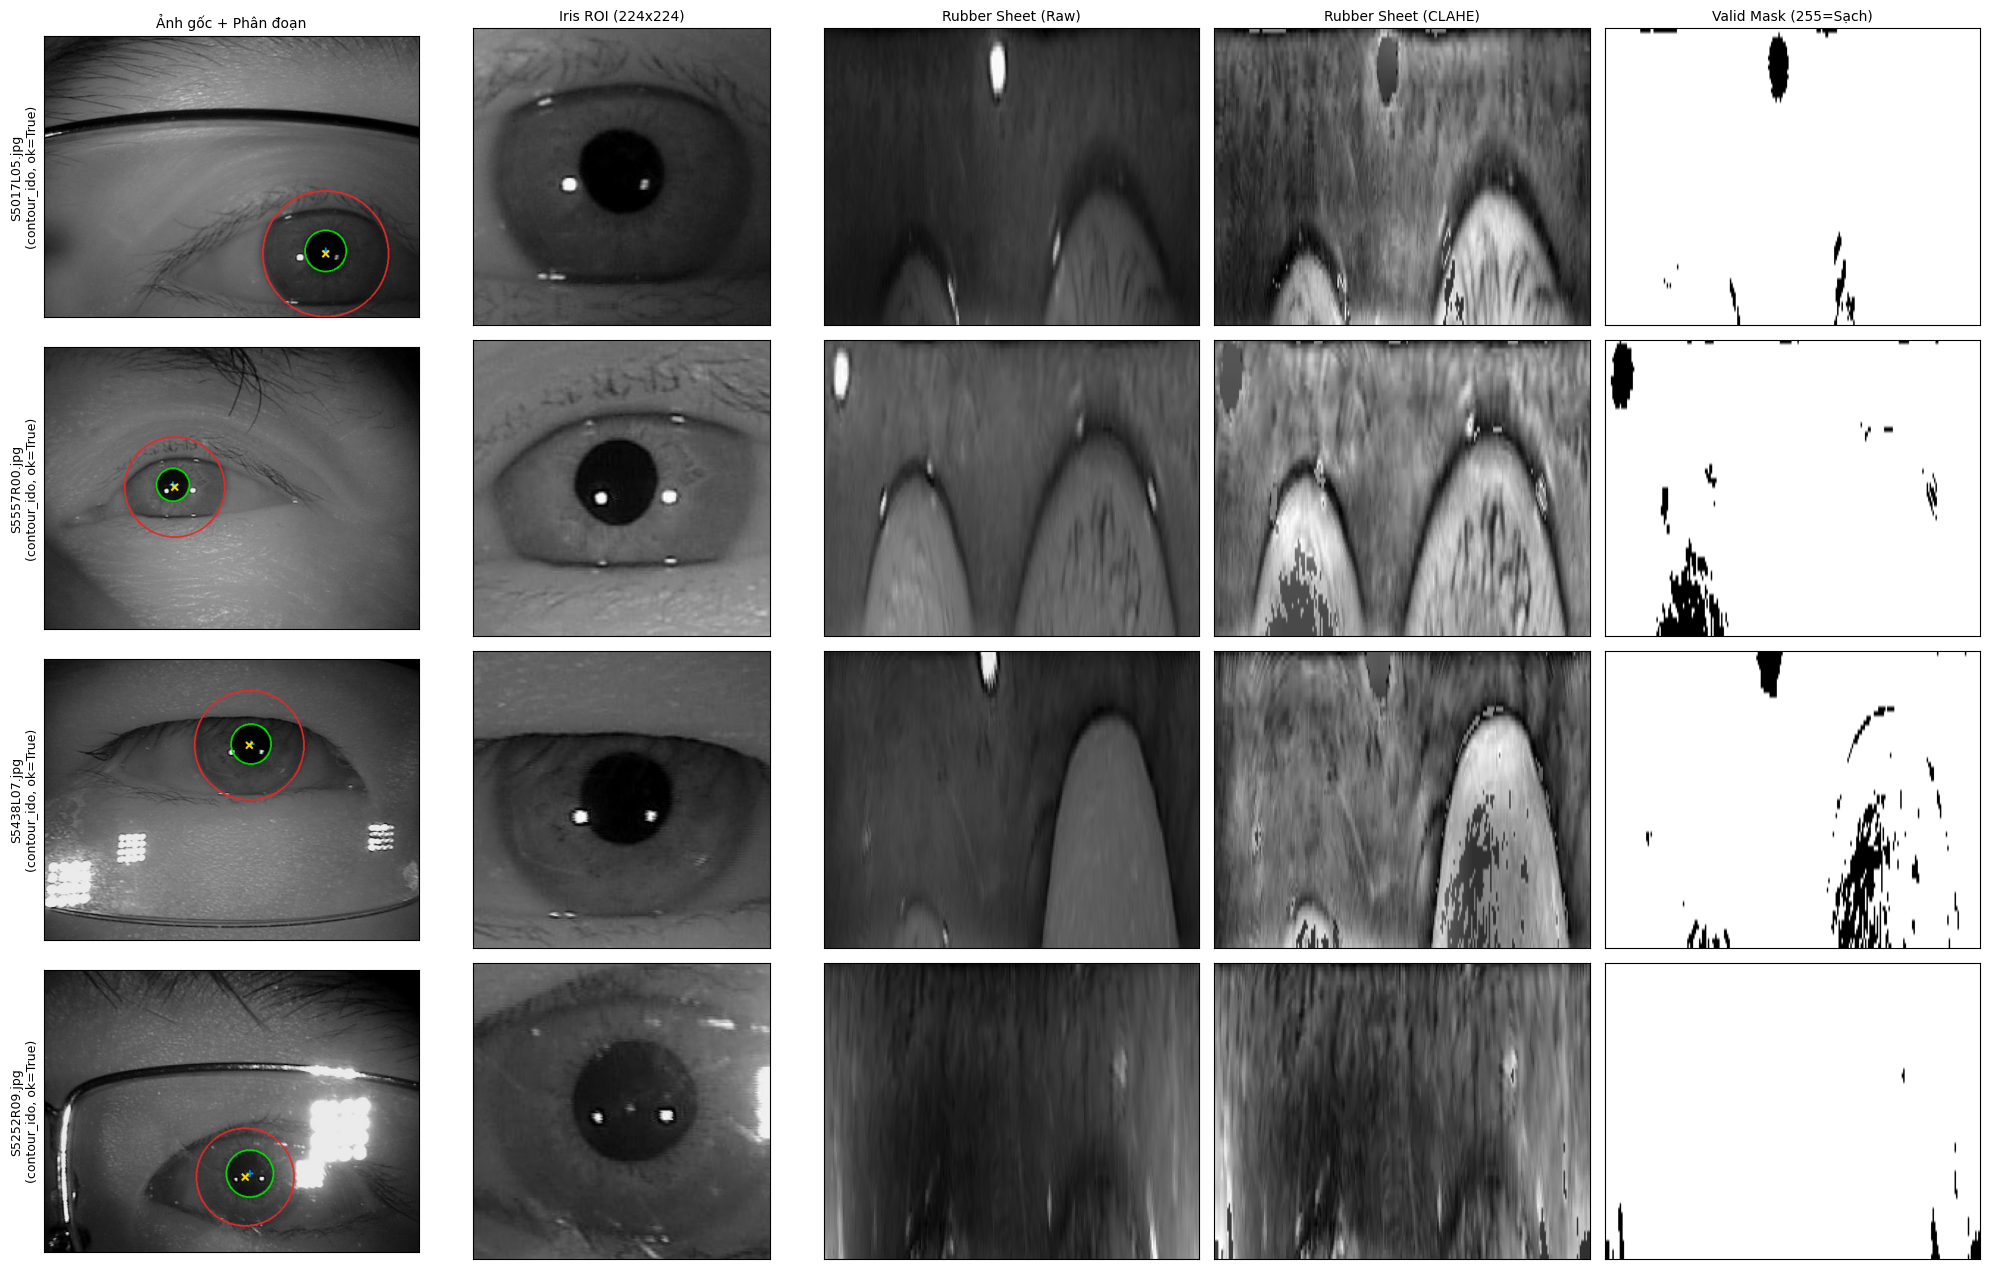

In [4]:
valid_meta = meta_df[meta_df["is_valid"].astype(bool)].copy()
clean_samples = valid_meta.nsmallest(2, "specular_ratio")
glare_samples = valid_meta.nlargest(2, "specular_ratio")
demo_rows = pd.concat([clean_samples, glare_samples], ignore_index=True)

fig, axes = plt.subplots(len(demo_rows), 5, figsize=(20, 3.2 * len(demo_rows)))
col_titles = [
    "Ảnh gốc + Phân đoạn",
    "Iris ROI (224x224)",
    "Rubber Sheet (Raw)",
    "Rubber Sheet (CLAHE)",
    "Valid Mask (255=Sạch)",
]

for r_idx, (_, row) in enumerate(demo_rows.iterrows()):
    out = preprocess_single_image(RAW_DATA_DIR / row["rel_path"], PREP_CONFIG)
    seg = out["seg"]
    overlay = draw_segmentation_overlay(out["gray"], seg)

    axes[r_idx, 0].imshow(overlay)
    axes[r_idx, 0].set_ylabel(
        f"{row['filename']}\n({seg.method}, ok={out['seg_success']})",
        fontsize=9,
    )
    axes[r_idx, 1].imshow(out["roi"], cmap="gray")
    axes[r_idx, 2].imshow(out["polar_raw"], cmap="gray", aspect="auto")
    axes[r_idx, 3].imshow(out["polar_enhanced"], cmap="gray", aspect="auto")
    axes[r_idx, 4].imshow(out["valid_mask"], cmap="gray", vmin=0, vmax=255, aspect="auto")

    for c_idx in range(5):
        if r_idx == 0:
            axes[r_idx, c_idx].set_title(col_titles[c_idx], fontsize=10)
        axes[r_idx, c_idx].set_xticks([])
        axes[r_idx, c_idx].set_yticks([])

plt.tight_layout()
plt.savefig(PREP_FIG_DIR / "pipeline_demo.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Thực thi tiền xử lý hàng loạt và thống kê chất lượng phân đoạn

Áp dụng quy trình tiền xử lý đa tiến trình trên toàn bộ tập ảnh, thống kê tỷ lệ phân đoạn hợp lệ, phân bố bán kính đồng tử/mống mắt và trực quan hóa nhóm mẫu đạt chuẩn cao nhất so với nhóm mẫu gặp khó khăn.

In [5]:
num_workers = max(1, os.cpu_count() or 2)
print(f"Chạy tiền xử lý với {num_workers} tiến trình song song...")

seg_df = preprocess_dataset(
    metadata_csv=METADATA_CSV,
    raw_dir=RAW_DATA_DIR,
    output_dir=PROCESSED_DIR,
    cfg=PREP_CONFIG,
    num_workers=num_workers,
    show_progress=True,
)

with open(PROCESSED_DIR / "preprocessing_summary.json", "r", encoding="utf-8") as f:
    prep_summary = json.load(f)

print("\n=== TỔNG KẾT TIỀN XỬ LÝ ===")
print(
    f"Tỷ lệ phân đoạn đạt chuẩn: {prep_summary['seg_success_count']:,} / "
    f"{prep_summary['total_processed']:,} ({prep_summary['seg_success_rate']*100:.2f}%)"
)
print("Phương pháp định vị      :", prep_summary["method_counts"])
print("Thống kê bán kính đồng tử:", prep_summary["pupil_r_stats"])
print("Thống kê bán kính mống   :", prep_summary["iris_r_stats"])
print("Tỷ lệ điểm ảnh hợp lệ    :", prep_summary["valid_pixel_ratio_stats"])

Chạy tiền xử lý với 2 tiến trình song song...


Preprocessing images:   0%|          | 0/20000 [00:00<?, ?it/s]


=== TỔNG KẾT TIỀN XỬ LÝ ===
Tỷ lệ phân đoạn đạt chuẩn: 19,333 / 20,000 (96.67%)
Phương pháp định vị      : {'contour_ido': 19731, 'hough_ido': 269}
Thống kê bán kính đồng tử: {'mean': 35.9067, 'std': 8.018, 'min': 18.0, 'median': 35.0, 'max': 75.0}
Thống kê bán kính mống   : {'mean': 94.1136, 'std': 7.9148, 'min': 65.0, 'median': 94.0, 'max': 155.0}
Tỷ lệ điểm ảnh hợp lệ    : {'mean': 0.9596, 'std': 0.0445, 'min': 0.2523, 'median': 0.9758, 'max': 1.0}


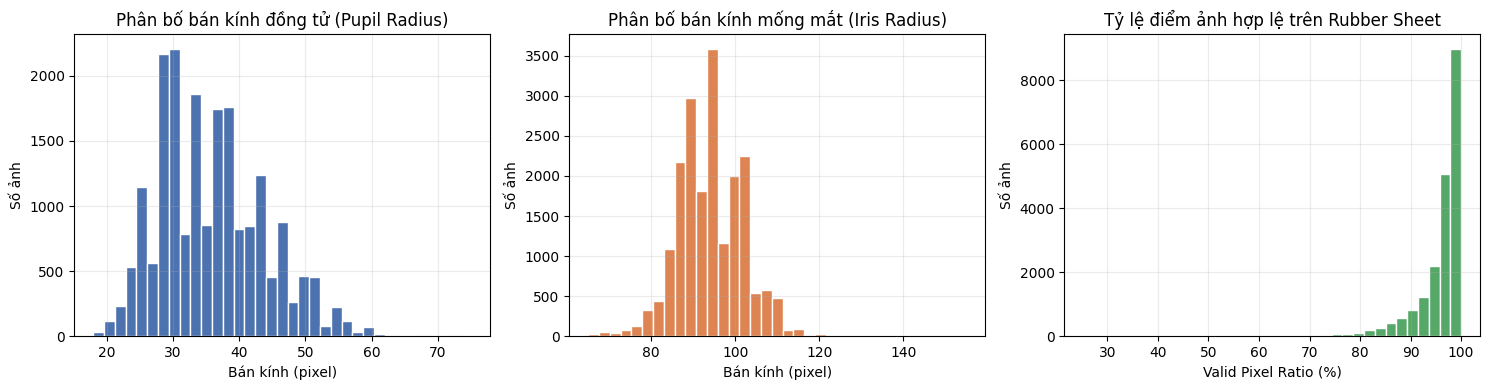

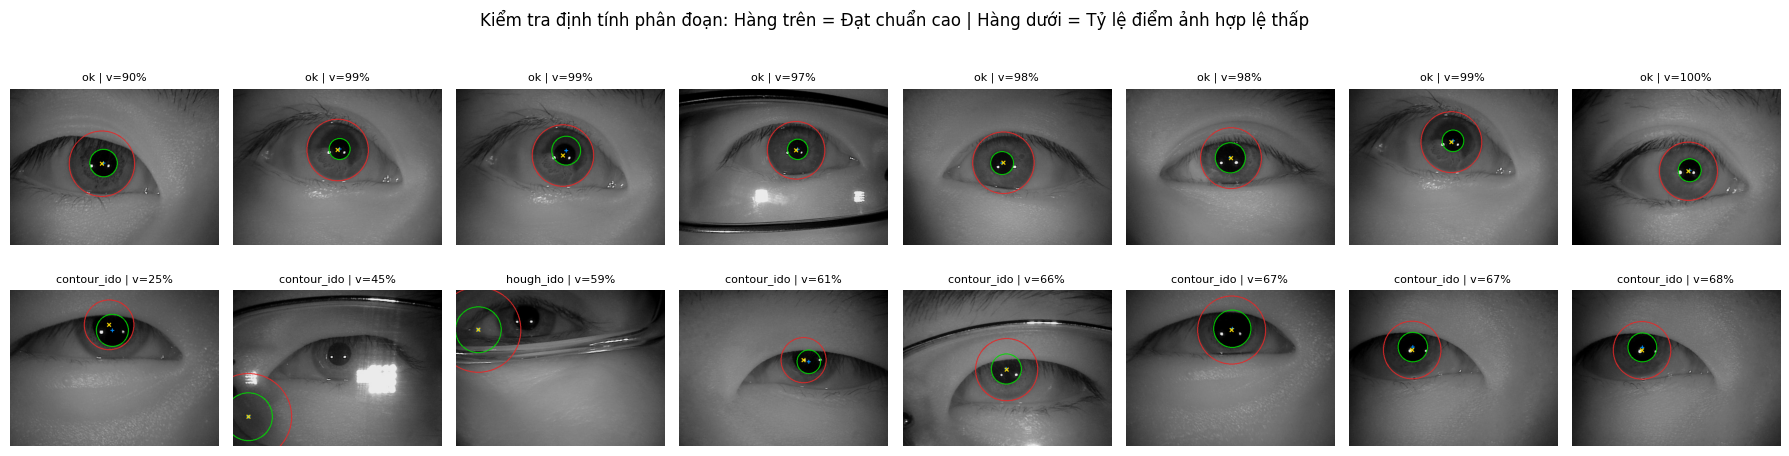

In [6]:
# Biểu đồ thống kê hình học phân đoạn và tỷ lệ điểm ảnh hợp lệ
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(seg_df["pupil_r"].dropna(), bins=35, color="#4C72B0", edgecolor="white")
axes[0].set_title("Phân bố bán kính đồng tử (Pupil Radius)")
axes[0].set_xlabel("Bán kính (pixel)")

axes[1].hist(seg_df["iris_r"].dropna(), bins=35, color="#DD8452", edgecolor="white")
axes[1].set_title("Phân bố bán kính mống mắt (Iris Radius)")
axes[1].set_xlabel("Bán kính (pixel)")

axes[2].hist(seg_df["valid_pixel_ratio"] * 100.0, bins=35, color="#55A868", edgecolor="white")
axes[2].set_title("Tỷ lệ điểm ảnh hợp lệ trên Rubber Sheet")
axes[2].set_xlabel("Valid Pixel Ratio (%)")

for ax in axes:
    ax.set_ylabel("Số ảnh")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(PREP_FIG_DIR / "segmentation_stats.png", dpi=150, bbox_inches="tight")
plt.show()

# Lưới kiểm tra định tính: 8 mẫu điểm cao nhất và 8 mẫu điểm/tỷ lệ hợp lệ thấp nhất
ranked_df = seg_df.dropna(subset=["iris_score"]).copy()
top_ok = ranked_df[ranked_df["seg_success"]].nlargest(8, "iris_score")
low_qa = ranked_df.nsmallest(8, "valid_pixel_ratio")

fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for col_idx, (_, row) in enumerate(top_ok.iterrows()):
    img = cv2.imread(str(RAW_DATA_DIR / row["rel_path"]), cv2.IMREAD_GRAYSCALE)
    seg_obj = SegmentationResult(
        pupil_x=float(row["pupil_x"]),
        pupil_y=float(row["pupil_y"]),
        pupil_r=float(row["pupil_r"]),
        iris_x=float(row["iris_x"]),
        iris_y=float(row["iris_y"]),
        iris_r=float(row["iris_r"]),
        pupil_score=float(row["pupil_score"]),
        iris_score=float(row["iris_score"]),
        method=str(row["seg_method"]),
        success=bool(row["seg_success"]),
    )
    axes[0, col_idx].imshow(draw_segmentation_overlay(img, seg_obj))
    axes[0, col_idx].set_title(f"ok | v={row['valid_pixel_ratio']*100:.0f}%", fontsize=8)
    axes[0, col_idx].axis("off")

for col_idx, (_, row) in enumerate(low_qa.iterrows()):
    img = cv2.imread(str(RAW_DATA_DIR / row["rel_path"]), cv2.IMREAD_GRAYSCALE)
    seg_obj = SegmentationResult(
        pupil_x=float(row["pupil_x"]),
        pupil_y=float(row["pupil_y"]),
        pupil_r=float(row["pupil_r"]),
        iris_x=float(row["iris_x"]),
        iris_y=float(row["iris_y"]),
        iris_r=float(row["iris_r"]),
        pupil_score=float(row["pupil_score"]),
        iris_score=float(row["iris_score"]),
        method=str(row["seg_method"]),
        success=bool(row["seg_success"]),
    )
    axes[1, col_idx].imshow(draw_segmentation_overlay(img, seg_obj))
    axes[1, col_idx].set_title(f"{row['seg_method']} | v={row['valid_pixel_ratio']*100:.0f}%", fontsize=8)
    axes[1, col_idx].axis("off")

fig.suptitle("Kiểm tra định tính phân đoạn: Hàng trên = Đạt chuẩn cao | Hàng dưới = Tỷ lệ điểm ảnh hợp lệ thấp", fontsize=12)
plt.tight_layout()
plt.savefig(PREP_FIG_DIR / "segmentation_qa_grid.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Đóng gói và đồng bộ dữ liệu đã xử lý

Nén toàn bộ ảnh Rubber Sheet, mặt nạ và ROI thành một tệp nén duy nhất (`processed_casia_thousand.zip`) và lưu trữ cùng báo cáo thống kê, biểu đồ lên Google Drive phục vụ trực tiếp cho giai đoạn huấn luyện truyền thống và học sâu.

In [7]:
ZIP_LOCAL = DATA_ROOT / "processed_casia_thousand.zip"
archive_processed_dir(PROCESSED_DIR, ZIP_LOCAL)
zip_mb = ZIP_LOCAL.stat().st_size / (1024.0 * 1024.0)
print(f"Đã nén toàn bộ dữ liệu tiền xử lý: {ZIP_LOCAL} ({zip_mb:.2f} MB)")

if DRIVE_PROJECT_DIR is not None:
    drive_prep = DRIVE_PROJECT_DIR / "preprocessing"
    drive_prep.mkdir(parents=True, exist_ok=True)

    shutil.copy2(ZIP_LOCAL, DRIVE_PROJECT_DIR / "processed_casia_thousand.zip")
    shutil.copy2(PROCESSED_DIR / "segmentation_metadata.csv", drive_prep / "segmentation_metadata.csv")
    shutil.copy2(PROCESSED_DIR / "preprocessing_summary.json", drive_prep / "preprocessing_summary.json")
    for fig_path in PREP_FIG_DIR.glob("*.png"):
        shutil.copy2(fig_path, drive_prep / fig_path.name)

    print(f"Đã đồng bộ tệp nén -> {DRIVE_PROJECT_DIR / 'processed_casia_thousand.zip'}")
    print(f"Đã đồng bộ thống kê và biểu đồ -> {drive_prep}")

Đã nén toàn bộ dữ liệu tiền xử lý: /content/data/processed_casia_thousand.zip (459.58 MB)
Đã đồng bộ tệp nén -> /content/drive/MyDrive/prj3/processed_casia_thousand.zip
Đã đồng bộ thống kê và biểu đồ -> /content/drive/MyDrive/prj3/preprocessing
